# Chapitre 10 - Cours 3 : interpréter un modèle boosté (spam et données immobilières simulées)

Ce notebook illustre les sections 10.7, 10.8, 10.13 et 10.14 du livre :

1. pourquoi les arbres boostés sont une méthode « clé en main » pour la fouille de données ;
2. le gradient boosting sur les données **spam** (section 10.8) ;
3. l'**importance relative** des variables (éq. (10.42)–(10.43), figure 10.6) ;
4. les **graphes de dépendance partielle** (éq. (10.47)–(10.49), figures 10.7 et 10.8) ;
5. une étude complète sur des **données immobilières simulées**, construites sur le
   modèle des données *California Housing* de la section 10.14.1 (non disponibles ici).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl.ch10_boosting import (GradientBoosting, RegressionTree, SPAM_NAMES,
                               partial_dependence_bruteforce)

## 1. Des méthodes « clé en main » pour la fouille de données

Les données réelles de la fouille de données (*data mining*) sont souvent volumineuses,
hétérogènes (variables quantitatives et qualitatives), avec des valeurs manquantes, des
distributions très asymétriques, des valeurs aberrantes et beaucoup de variables
inutiles. Le tableau 10.1 du livre compare les méthodes selon ces critères.

Les **arbres de décision** cochent presque toutes les cases : rapides, interprétables
(s'ils sont petits), invariants par transformation monotone des prédicteurs (donc
insensibles aux échelles et aux valeurs extrêmes des $X_j$), sélection de variables
intégrée. Leur défaut est leur **imprécision**. Le boosting améliore fortement la
précision tout en conservant la plupart de ces qualités ; on perd en revanche
l'interprétabilité immédiate, d'où les outils de la section 10.13.

## 2. Les données spam

4601 messages électroniques, dont 39,4 % de spams ; les 57 prédicteurs sont des fréquences
de mots (`george`, `hp`, `remove`, `free`…) et de caractères (`!`, `$`…) ainsi que trois
statistiques sur les suites de majuscules (`CAPAVE`, `CAPMAX`, `CAPTOT`). Le livre utilise une
séparation apprentissage/test précise (1536 messages de test) que nous n'avons pas : nous
tirons au hasard 1536 messages de test.

In [2]:
spam = datasets.load_spam()
Xs = spam.drop(columns="spam").to_numpy(float)
ys = spam["spam"].to_numpy()
rng = np.random.RandomState(0)
perm = rng.permutation(len(ys))
test_idx, train_idx = perm[:1536], perm[1536:]
Xs_tr, ys_tr = Xs[train_idx], ys[train_idx]
Xs_te, ys_te = Xs[test_idx], ys[test_idx]
print("apprentissage :", Xs_tr.shape, "| test :", Xs_te.shape, "| proportion de spams : %.3f" % ys.mean())

apprentissage : (3065, 57) | test : (1536, 57) | proportion de spams : 0.394


On modélise le **log-rapport de cotes**

$$f(x) = \log\frac{P(\text{spam}\mid x)}{P(\text{email}\mid x)} \qquad \text{(éq. (10.24))}$$

par gradient boosting avec la déviance binomiale, des arbres à $J = 5$ feuilles, un
rétrécissement $\nu = 0{,}1$ et un sous-échantillonnage $\eta = 0{,}5$.

In [3]:
M_spam = 1000
gb5 = GradientBoosting("deviance", M_spam, 5, learning_rate=0.1, subsample=0.5,
                       random_state=0).fit(Xs_tr, ys_tr)
its5, dev5, err5 = gb5.staged_scores(Xs_te, ys_te, every=10)
gb2 = GradientBoosting("deviance", M_spam, 2, learning_rate=0.1, subsample=0.5,
                       random_state=0).fit(Xs_tr, ys_tr)
its2, dev2, err2 = gb2.staged_scores(Xs_te, ys_te, every=10)

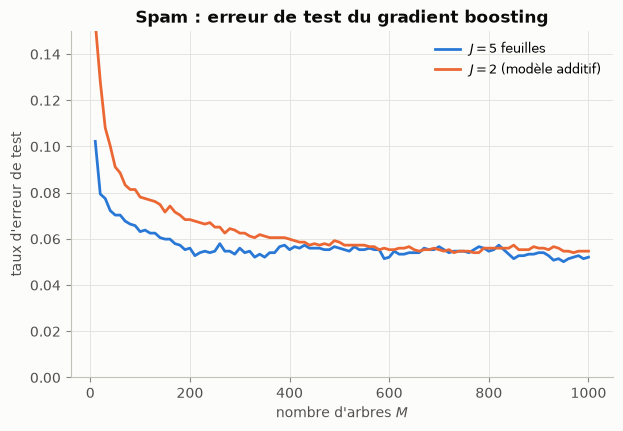

J = 5 : erreur de test après 1000 arbres = 0.052 (minimum 0.050)
J = 2 : erreur de test après 1000 arbres = 0.055 (minimum 0.054)


In [4]:
plt.figure(figsize=(7, 4.5))
plt.plot(its5, err5, color=BLUE, label="$J = 5$ feuilles")
plt.plot(its2, err2, color=ORANGE, label="$J = 2$ (modèle additif)")
plt.ylim(0, 0.15)
plt.title("Spam : erreur de test du gradient boosting")
plt.xlabel("nombre d'arbres $M$")
plt.ylabel("taux d'erreur de test")
plt.legend()
plt.show()
print("J = 5 : erreur de test après %d arbres = %.3f (minimum %.3f)" % (M_spam, err5[-1], err5.min()))
print("J = 2 : erreur de test après %d arbres = %.3f (minimum %.3f)" % (M_spam, err2[-1], err2.min()))

Le livre obtient 4,5 % avec $J = 5$ et 4,7 % avec des souches (modèle purement additif),
contre 5,5 % pour un modèle additif généralisé, 5,5 % pour MARS et 8,7 % pour un arbre
CART élagué. Nos chiffres, obtenus sur une autre séparation aléatoire, sont du même ordre.
L'erreur standard d'un taux d'environ 5 % estimé sur 1536 messages est
$\sqrt{0{,}05 \times 0{,}95/1536} \approx 0{,}6\,\%$ (exercice 10.6).

Pour comparaison, un arbre seul de taille moyenne :

In [5]:
for J in (5, 20, 60):
    t = RegressionTree(J, min_leaf=5).fit(Xs_tr, ys_tr.astype(float))
    print("arbre à %2d feuilles : erreur de test = %.3f" % (J, np.mean((t.predict(Xs_te) > 0.5) != ys_te)))

arbre à  5 feuilles : erreur de test = 0.143
arbre à 20 feuilles : erreur de test = 0.089
arbre à 60 feuilles : erreur de test = 0.089


## 3. Importance relative des variables

### Pour un arbre

Dans un arbre $T$ à $J$ feuilles, chacun des $J - 1$ nœuds internes $t$ coupe selon une
variable $X_{v(t)}$ et fait baisser la somme des carrés d'une quantité $\hat\imath_t^2$
(l'« amélioration » de la coupure). Breiman et al. (1984) définissent l'importance
(au carré) de la variable $X_\ell$ par

$$\mathcal I_\ell^2(T) = \sum_{t=1}^{J-1}\hat\imath_t^2\, I\big(v(t) = \ell\big) \qquad \text{(éq. (10.42))} :$$

la somme des améliorations de toutes les coupures qui utilisent $X_\ell$.

### Pour une somme d'arbres

On moyenne simplement sur les $M$ arbres :

$$\mathcal I_\ell^2 = \frac1M\sum_{m=1}^M \mathcal I_\ell^2(T_m) \qquad \text{(éq. (10.43))}.$$

Grâce à la moyenne, cette mesure est plus stable que pour un arbre seul ; grâce au
rétrécissement, une variable importante est moins souvent « masquée » par une variable
corrélée. On représente les racines $\mathcal I_\ell$, normalisées pour que la plus grande vaille 100.

> **Remarque.** Pour $K$ classes, on calcule $\mathcal I_{\ell k}$ pour chaque fonction $f_k$
> (éq. (10.45)) puis on moyenne sur les classes (éq. (10.46)).

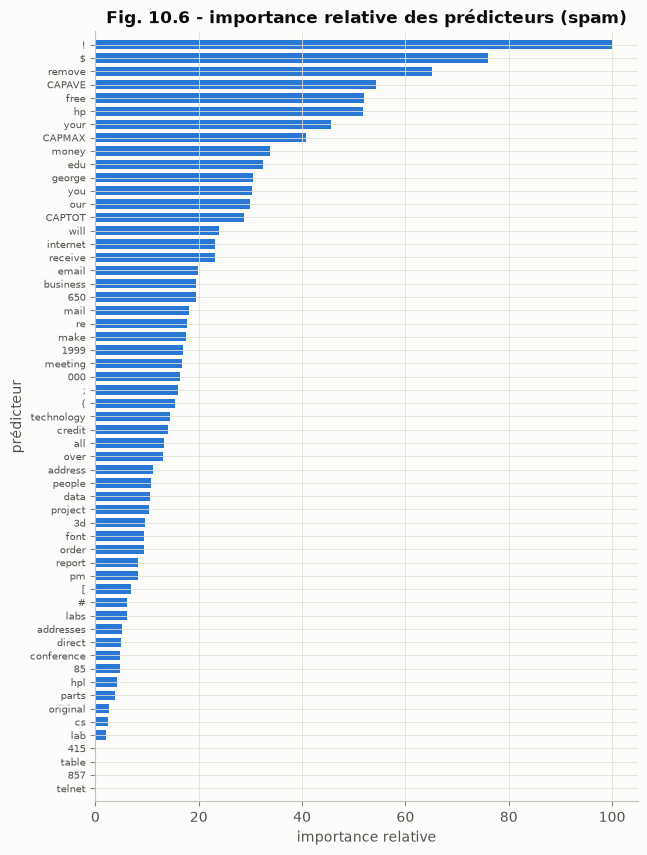

In [6]:
imp = gb5.feature_importances()
order = np.argsort(imp)
fig, ax = plt.subplots(figsize=(7, 10))
ax.barh(np.arange(57), imp[order], color=BLUE, height=0.7)
ax.set_yticks(np.arange(57))
ax.set_yticklabels([SPAM_NAMES[k] for k in order], fontsize=7)
ax.set_title("Fig. 10.6 - importance relative des prédicteurs (spam)")
ax.set_xlabel("importance relative")
ax.set_ylabel("prédicteur")
ax.set_ylim(-1, 57)
plt.show()

In [7]:
top = np.argsort(imp)[::-1][:8]
print("8 variables les plus importantes :", [SPAM_NAMES[k] for k in top])
print("4 moins importantes              :", [SPAM_NAMES[k] for k in np.argsort(imp)[:4]])

8 variables les plus importantes : ['!', '$', 'remove', 'CAPAVE', 'free', 'hp', 'your', 'CAPMAX']
4 moins importantes              : ['telnet', '857', 'table', '415']


Comme dans le livre, les fréquences de `!`, `$`, `hp` et `remove` figurent parmi les
prédicteurs les plus importants, tandis que des chaînes comme `3d`, `table` ou `857`
n'ont pratiquement aucun rôle.

## 4. Dépendance partielle

### Définition

Soit $X_S$ un sous-vecteur de $\ell < p$ variables, indicé par $S\subset\{1,\dots,p\}$, et $C$ le
complémentaire : $f(X) = f(X_S, X_C)$. La **dépendance partielle** de $f$ sur $X_S$ est

$$f_S(X_S) = E_{X_C} f(X_S, X_C) \qquad \text{(éq. (10.47))},$$

la moyenne de $f$ sur la loi **marginale** de $X_C$, à $X_S$ fixé. On l'estime par

$$\bar f_S(X_S) = \frac1N\sum_{i=1}^N f(X_S, x_{iC}) \qquad \text{(éq. (10.48))} :$$

on remplace, dans chaque observation d'apprentissage, les variables de $S$ par la valeur
voulue et l'on moyenne les prédictions.

### À ne pas confondre avec l'espérance conditionnelle

$$\tilde f_S(X_S) = E\big(f(X_S, X_C)\mid X_S\big) \qquad \text{(éq. (10.49))}$$

est la meilleure approximation (au sens des moindres carrés) de $f$ par une fonction de
$X_S$ seul : elle mesure l'effet de $X_S$ **en ignorant** les autres variables, alors que
$f_S$ mesure l'effet de $X_S$ **après avoir tenu compte** (en moyenne) de $X_C$. Les deux
coïncident si $X_S$ et $X_C$ sont indépendants.

- Si $f(X) = h_1(X_S) + h_2(X_C)$ (éq. (10.50)), alors $f_S = h_1 + \text{constante}$ ;
- si $f(X) = h_1(X_S)\, h_2(X_C)$ (éq. (10.51)), alors $f_S = h_1 \times \text{constante}$ ;

alors que $\tilde f_S$ ne redonne $h_1$ dans aucun des deux cas (exercice 10.3), et peut même
afficher un effet de variables dont $f$ ne dépend pas (exercice 10.12).

Petite illustration : $f(X_1, X_2) = X_2$ avec $(X_1, X_2)$ gaussien de corrélation $0{,}8$.
La dépendance partielle sur $X_1$ est constante (car $f$ ne dépend pas de $X_1$), mais
l'espérance conditionnelle vaut $E(X_2\mid X_1) = 0{,}8\,X_1$.

In [8]:
rng = np.random.RandomState(0)
rho = 0.8
Z = rng.randn(4000, 2)
Xc = np.c_[Z[:, 0], rho * Z[:, 0] + np.sqrt(1 - rho ** 2) * Z[:, 1]]
f_simple = lambda A: A[:, 1]
g1 = np.linspace(-2.5, 2.5, 41)
pd_simple = partial_dependence_bruteforce(f_simple, Xc, [0], g1[:, None])
bins_c = np.digitize(Xc[:, 0], g1)
cond = np.array([f_simple(Xc)[bins_c == k].mean() if np.any(bins_c == k) else np.nan
                 for k in range(1, len(g1))])

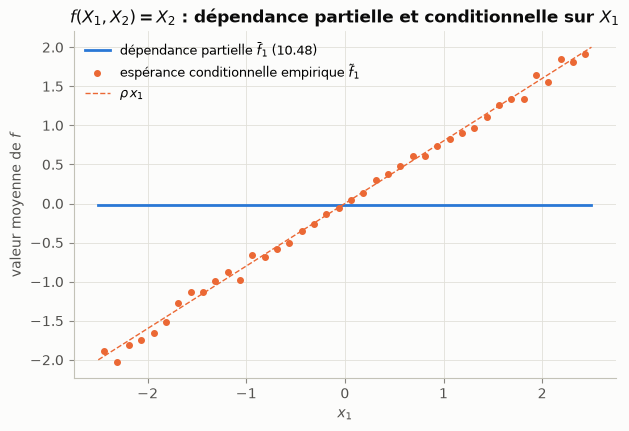

In [9]:
plt.figure(figsize=(7, 4.5))
plt.plot(g1, pd_simple, color=BLUE, label="dépendance partielle $\\bar f_1$ (10.48)")
plt.plot(0.5 * (g1[1:] + g1[:-1]), cond, "o", ms=4, color=ORANGE,
         label="espérance conditionnelle empirique $\\tilde f_1$")
plt.plot(g1, rho * g1, color=ORANGE, ls="--", lw=1, label="$\\rho\\, x_1$")
plt.title("$f(X_1, X_2) = X_2$ : dépendance partielle et conditionnelle sur $X_1$")
plt.xlabel("$x_1$")
plt.ylabel("valeur moyenne de $f$")
plt.legend()
plt.show()

### Calcul rapide pour les arbres (exercice 10.11)

L'estimateur (10.48) demande, pour **chaque** valeur de $x_S$, une prédiction sur les $N$
observations. Pour un arbre, Friedman propose un parcours **pondéré** sans les données :
on descend l'arbre depuis la racine avec un poids 1 ; à un nœud qui coupe selon une
variable de $S$, on suit la branche indiquée par $x_S$ ; sinon, on descend **des deux
côtés** en multipliant le poids par la fraction des observations d'apprentissage qui
passent dans chaque fils. La dépendance partielle est la moyenne pondérée des valeurs
des feuilles atteintes. Pour une somme d'arbres, on additionne.

Ce parcours suppose implicitement que, dans chaque nœud, la répartition des observations
entre les fils ne dépend pas des coupures sur $X_S$ faites plus haut : c'est une
approximation de (10.48), exacte lorsque $X_S$ et $X_C$ sont indépendants. Notre module
propose aussi une version **exacte** (voir l'exercice 10.11). Comparons-les.

In [10]:
k_excl = SPAM_NAMES.index("!")
grid_excl = np.linspace(0, 1, 6)[:, None]
pd_fast = gb5.partial_dependence(grid_excl, [k_excl])
pd_exact = gb5.partial_dependence(grid_excl, [k_excl], X=Xs_tr)
pd_brute = partial_dependence_bruteforce(gb5.decision_function, Xs_tr, [k_excl], grid_excl)
for g, a, b, c in zip(grid_excl[:, 0], pd_fast, pd_exact, pd_brute):
    print("! = %.1f : parcours pondéré %.3f | exact %.3f | moyenne (10.48) %.3f" % (g, a, b, c))

! = 0.0 : parcours pondéré -2.516 | exact -2.293 | moyenne (10.48) -2.293
! = 0.2 : parcours pondéré -1.326 | exact -1.534 | moyenne (10.48) -1.534
! = 0.4 : parcours pondéré -0.838 | exact -1.095 | moyenne (10.48) -1.095
! = 0.6 : parcours pondéré 0.311 | exact 0.038 | moyenne (10.48) 0.038
! = 0.8 : parcours pondéré 0.693 | exact 0.447 | moyenne (10.48) 0.447
! = 1.0 : parcours pondéré 1.542 | exact 1.275 | moyenne (10.48) 1.275


Le calcul exact coïncide avec la moyenne (10.48). Le parcours pondéré en diffère d'un
décalage de quelques dixièmes (les fréquences de mots du spam sont corrélées entre elles),
mais les **variations** d'un point de la grille à l'autre, qui seules s'interprètent,
sont proches. Les figures suivantes utilisent le parcours pondéré, le plus rapide.

### Figure 10.7 : dépendance partielle du log-rapport de cotes

Quatre prédicteurs importants : deux associés positivement au spam (`!`, `remove`) et deux
négativement (`edu`, `hp`). Les traits verticaux en bas indiquent les déciles de la variable.
Les courbes sont centrées (moyenne nulle sur la grille pondérée par les données).

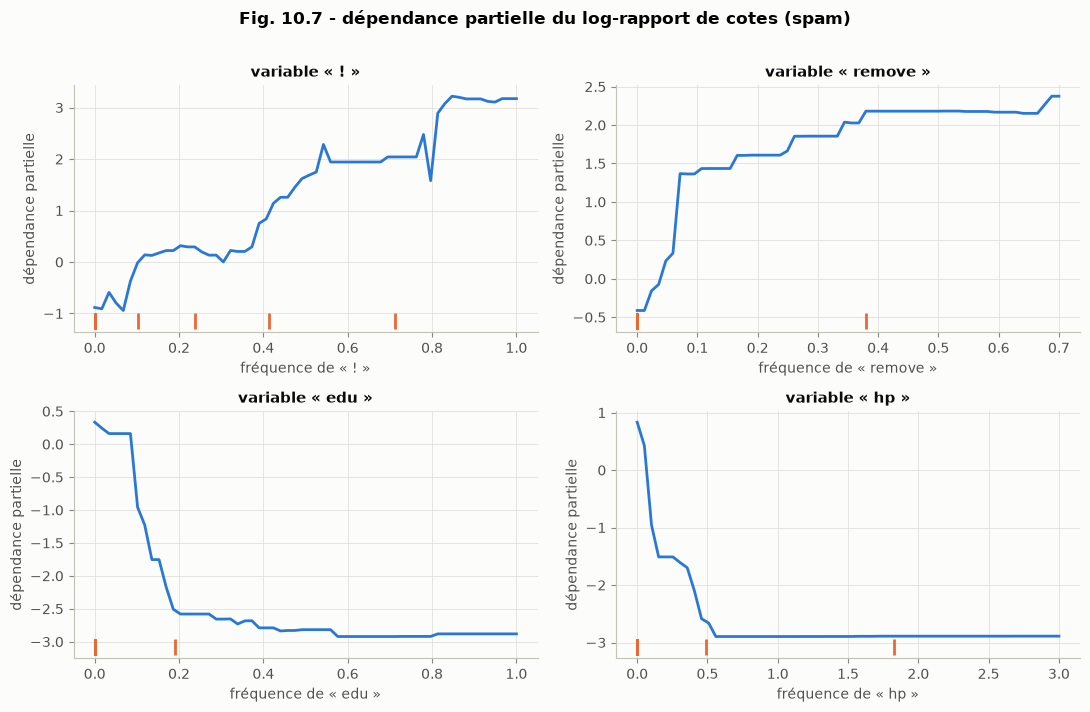

In [11]:
panels = [("!", 1.0), ("remove", 0.7), ("edu", 1.0), ("hp", 3.0)]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (name, xmax) in zip(axes.ravel(), panels):
    k = SPAM_NAMES.index(name)
    grid = np.linspace(0, xmax, 60)
    pd = gb5.partial_dependence(grid[:, None], [k])
    pd_at_data = gb5.partial_dependence(np.clip(Xs_tr[:, k], 0, xmax)[:, None], [k])
    ax.plot(grid, pd - pd_at_data.mean(), color=BLUE)
    dec = np.percentile(Xs_tr[:, k], np.arange(10, 100, 10))
    ax.plot(dec[dec <= xmax], np.full((dec <= xmax).sum(), ax.get_ylim()[0]), "|",
            color=ORANGE, ms=12, mew=2)
    ax.set_title("variable « %s »" % name, fontsize=11)
    ax.set_xlabel("fréquence de « %s »" % name)
    ax.set_ylabel("dépendance partielle")
fig.suptitle("Fig. 10.7 - dépendance partielle du log-rapport de cotes (spam)", fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

Les dépendances sont essentiellement **monotones** : plus il y a de `!` ou de `remove`,
plus le message a de chances d'être un spam ; plus il y a de `hp` (le nom de l'entreprise
du destinataire) ou de `edu`, moins il en a. On retrouve les formes du modèle additif
logistique de la figure 9.1 du livre.

### Figure 10.8 : dépendance partielle conjointe de `hp` et `!`

Avec des souches, l'erreur est un peu plus grande qu'avec $J = 5$ : il existe peut-être des
**interactions**. Une dépendance partielle à deux variables permet de les diagnostiquer.

In [12]:
kh, ke = SPAM_NAMES.index("hp"), SPAM_NAMES.index("!")
gh = np.linspace(0, 3, 40)
ge = np.linspace(0, 1, 40)
HH, EE = np.meshgrid(gh, ge)
pd2 = gb5.partial_dependence(np.c_[HH.ravel(), EE.ravel()], [kh, ke]).reshape(HH.shape)
pd2 -= pd2.mean()

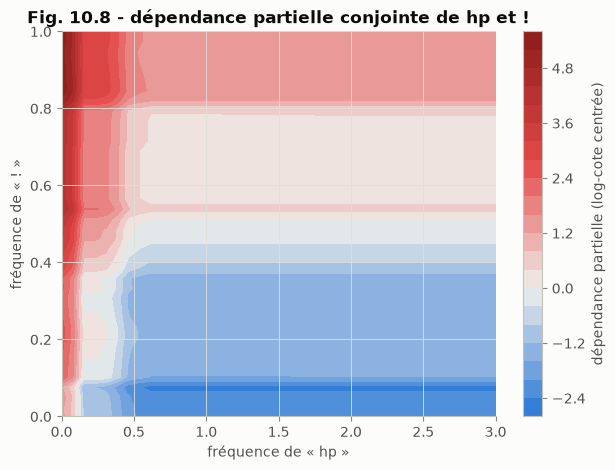

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
lim = np.abs(pd2).max()
cs = ax.contourf(HH, EE, pd2, levels=21, cmap=DIV, vmin=-lim, vmax=lim)
fig.colorbar(cs, ax=ax, label="dépendance partielle (log-cote centrée)")
ax.set_title("Fig. 10.8 - dépendance partielle conjointe de hp et !")
ax.set_xlabel("fréquence de « hp »")
ax.set_ylabel("fréquence de « ! »")
plt.show()

Pour de très faibles fréquences de `hp`, le log-rapport de cotes croît très fortement avec
`!` ; dès que `hp` dépasse environ 0,5, il est globalement plus bas et l'effet de `!` est
nettement atténué. Une dépendance purement additive donnerait le même écart vertical entre
deux niveaux de `!` quelle que soit la valeur de `hp` ; ici cet écart dépend du niveau de
`hp` : c'est une **interaction**, comme dans la figure 10.8 du livre.

## 5. Une étude complète : données immobilières simulées

La section 10.14.1 du livre analyse les données *California Housing* : la valeur médiane
des logements de 20 460 quartiers en fonction de 8 prédicteurs. Ces données n'étant pas
disponibles ici, nous **simulons** un jeu de données de même structure, avec un modèle
connu qui reproduit les effets décrits dans le livre :

- effet croissant et concave du revenu médian `MedInc` ;
- effet de la **localisation** (`Latitude`, `Longitude`) : prix élevés près de la côte et
  autour de deux grandes agglomérations ;
- effet décroissant de l'occupation moyenne `AveOccup`, et **interaction** avec l'âge des
  logements `HouseAge` (l'âge ne compte que lorsque l'occupation est faible) ;
- des variables sans effet propre (`Population`, `AveBedrms`, et `AveRooms` qui n'agit
  qu'à travers sa corrélation avec le revenu) ;
- un bruit à queues lourdes (loi de Student), d'où le choix de la perte de **Huber**.

In [14]:
def simulate_housing(n, rng):
    """Données immobilières simulées (8 prédicteurs, valeur en centaines de milliers)."""
    medinc = np.clip(np.exp(1.2 + 0.45 * rng.randn(n)), 0.5, 15)
    age = rng.randint(1, 53, n).astype(float)
    rooms = 3.5 + 0.4 * medinc + rng.gamma(2, 0.4, n)
    bedrms = 0.18 * rooms + 0.1 * rng.rand(n)
    pop = np.exp(7 + 0.7 * rng.randn(n))
    occup = 1.5 + rng.gamma(2.0, 0.6, n)
    # localisation : deux agglomérations côtières et un arrière-pays
    comp = rng.choice(3, n, p=[0.35, 0.25, 0.40])
    lat = np.where(comp == 0, 34.0 + 0.4 * rng.randn(n),
                   np.where(comp == 1, 37.7 + 0.4 * rng.randn(n), rng.uniform(32.6, 41.9, n)))
    coast = -117.2 - 1.05 * (lat - 32.6)                   # longitude de la « côte »
    lon = np.where(comp < 2, coast + 0.8 * rng.rand(n), coast + rng.uniform(0, 4.0, n))
    dist_coast = np.maximum(lon - coast, 0)
    metro = (np.exp(-((lat - 34.0) ** 2 + (lon + 118.3) ** 2) / 0.3)
             + np.exp(-((lat - 37.7) ** 2 + (lon + 122.3) ** 2) / 0.3))
    f = (1.6 * np.log1p(medinc / 2)
         + 0.9 * np.exp(-dist_coast / 0.8) + 0.6 * metro
         - 0.35 * np.log(occup)
         + 0.25 * np.maximum(0, 3.0 - occup) * age / 52)
    y = np.clip(f + 0.25 * rng.standard_t(3, n), 0.15, 5.0)
    X = np.c_[medinc, age, rooms, bedrms, pop, occup, lat, lon]
    return X, y, f

HOUSING_NAMES = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population",
                 "AveOccup", "Latitude", "Longitude"]
rng = np.random.RandomState(0)
Xh, yh, fh = simulate_housing(10000, rng)
ntr = 8000
Xh_tr, yh_tr, Xh_te, yh_te = Xh[:ntr], yh[:ntr], Xh[ntr:], yh[ntr:]
print("valeur médiane : %.2f ; écart absolu moyen à la médiane : %.2f"
      % (np.median(yh), np.mean(np.abs(yh - np.median(yh)))))

valeur médiane : 1.91 ; écart absolu moyen à la médiane : 0.57


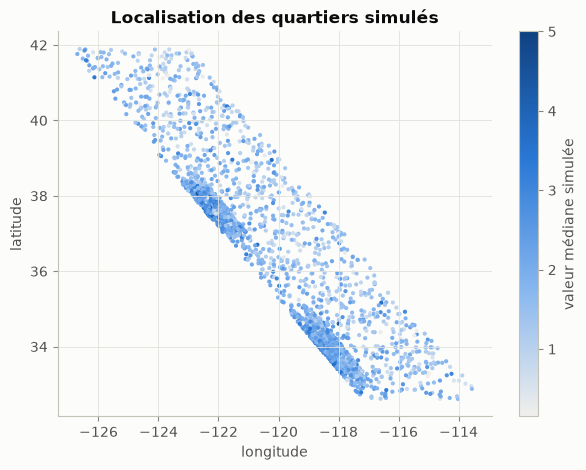

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(Xh[:3000, 7], Xh[:3000, 6], c=yh[:3000], s=4, cmap=SEQ)
fig.colorbar(sc, ax=ax, label="valeur médiane simulée")
ax.set_title("Localisation des quartiers simulés")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
plt.show()

Comme dans le livre : perte de Huber, arbres à $J = 6$ feuilles, $\nu = 0{,}1$, 80 % des
données en apprentissage et 20 % en test. On suit l'**erreur absolue moyenne**

$$\mathrm{AAE} = E\,\big|y - \hat f_M(x)\big| \qquad \text{(éq. (10.53))}.$$

In [16]:
M_h = 800
gbh = GradientBoosting("huber", M_h, 6, learning_rate=0.1, random_state=0).fit(Xh_tr, yh_tr)
aae_tr = [np.mean(np.abs(yh_tr - f)) for f in gbh.staged_decision_function(Xh_tr)]
aae_te = [np.mean(np.abs(yh_te - f)) for f in gbh.staged_decision_function(Xh_te)]

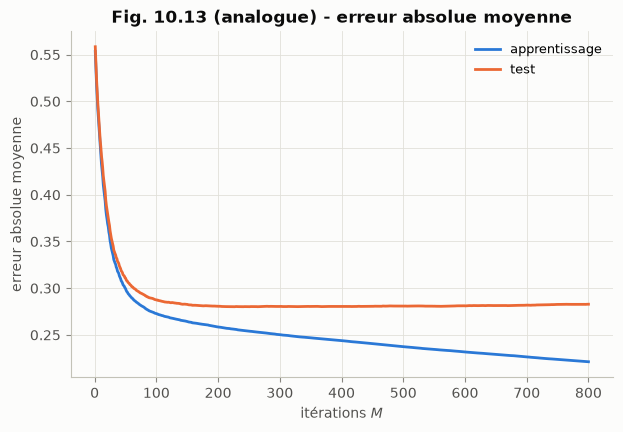

AAE test après 800 itérations : 0.283 (constante optimale : 0.579) ; R^2 test = 0.71


In [17]:
plt.figure(figsize=(7, 4.5))
plt.plot(np.arange(1, M_h + 1), aae_tr, color=BLUE, label="apprentissage")
plt.plot(np.arange(1, M_h + 1), aae_te, color=ORANGE, label="test")
plt.title("Fig. 10.13 (analogue) - erreur absolue moyenne")
plt.xlabel("itérations $M$")
plt.ylabel("erreur absolue moyenne")
plt.legend()
plt.show()
r2 = 1 - np.mean((yh_te - gbh.decision_function(Xh_te)) ** 2) / np.var(yh_te)
print("AAE test après %d itérations : %.3f (constante optimale : %.3f) ; R^2 test = %.2f"
      % (M_h, aae_te[-1], np.mean(np.abs(yh_te - np.median(yh_tr))), r2))

L'erreur de test décroît puis se stabilise : avec le rétrécissement, le choix exact de
$M$ n'est pas critique (pourvu qu'il ne soit pas trop petit), comme dans le livre.

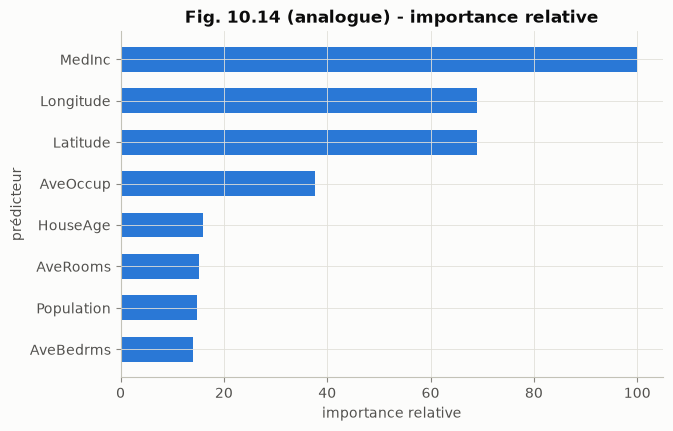

In [18]:
imp_h = gbh.feature_importances()
oh = np.argsort(imp_h)
plt.figure(figsize=(7, 4.5))
plt.barh(np.arange(8), imp_h[oh], color=BLUE, height=0.6)
plt.yticks(np.arange(8), [HOUSING_NAMES[k] for k in oh])
plt.title("Fig. 10.14 (analogue) - importance relative")
plt.xlabel("importance relative")
plt.ylabel("prédicteur")
plt.show()

Le revenu médian domine, suivi de la localisation et de l'occupation ; `Population` et
`AveBedrms` sont presque inutiles, comme le veut le modèle simulé. `AveRooms` reçoit une
importance non nulle bien qu'elle n'intervienne pas dans $f$ : elle est corrélée au revenu
et sert parfois de substitut. L'importance mesure l'usage d'une variable par le modèle,
pas une causalité.

### Dépendances partielles (analogue des figures 10.15 à 10.17)

Nous connaissons ici la vraie fonction : comparons les dépendances partielles estimées aux
dépendances partielles **vraies** de $f$, calculées par (10.48) sur la vraie fonction.

In [19]:
def f_true_housing(X):
    lat, lon = X[:, 6], X[:, 7]
    coast = -117.2 - 1.05 * (lat - 32.6)
    dist_coast = np.maximum(lon - coast, 0)
    metro = (np.exp(-((lat - 34.0) ** 2 + (lon + 118.3) ** 2) / 0.3)
             + np.exp(-((lat - 37.7) ** 2 + (lon + 122.3) ** 2) / 0.3))
    return (1.6 * np.log1p(X[:, 0] / 2) + 0.9 * np.exp(-dist_coast / 0.8) + 0.6 * metro
            - 0.35 * np.log(X[:, 5]) + 0.25 * np.maximum(0, 3.0 - X[:, 5]) * X[:, 1] / 52)

print("vérification : max |f_true - f simulée| =", np.max(np.abs(f_true_housing(Xh) - fh)))

vérification : max |f_true - f simulée| = 0.0


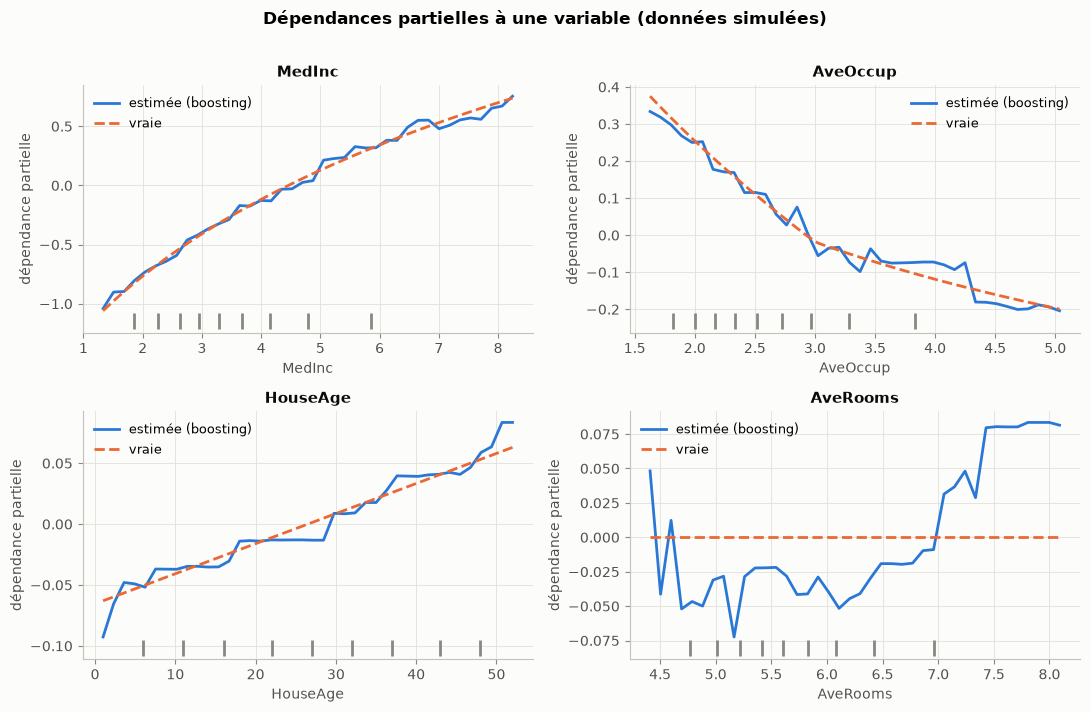

In [20]:
sub = Xh_tr[:1000]          # sous-échantillon pour la dépendance partielle vraie (10.48)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, k in zip(axes.ravel(), [0, 5, 1, 2]):
    lo, hi = np.percentile(Xh_tr[:, k], [2, 98])
    grid = np.linspace(lo, hi, 40)
    est = gbh.partial_dependence(grid[:, None], [k])
    tru = partial_dependence_bruteforce(f_true_housing, sub, [k], grid[:, None])
    ax.plot(grid, est - est.mean(), color=BLUE, label="estimée (boosting)")
    ax.plot(grid, tru - tru.mean(), color=ORANGE, ls="--", label="vraie")
    dec = np.percentile(Xh_tr[:, k], np.arange(10, 100, 10))
    ax.plot(dec, np.full(9, ax.get_ylim()[0]), "|", color=GRAY, ms=12, mew=2)
    ax.set_title(HOUSING_NAMES[k], fontsize=11)
    ax.set_xlabel(HOUSING_NAMES[k])
    ax.set_ylabel("dépendance partielle")
    ax.legend()
fig.suptitle("Dépendances partielles à une variable (données simulées)", fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

Les effets du revenu (concave) et de l'occupation (décroissante) sont bien retrouvés ;
celui de l'âge est faible et croissant (il n'agit que par l'interaction) ; `AveRooms` a une
dépendance partielle presque plate, ce qui est cohérent avec la vraie fonction.

### Interaction `HouseAge` × `AveOccup` (analogue de la figure 10.16)

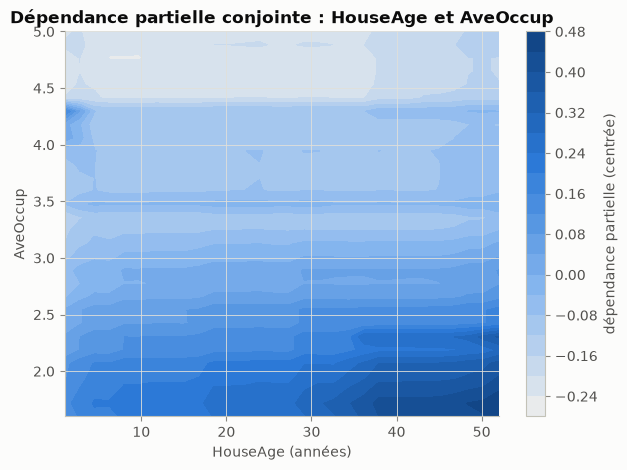

In [21]:
ga = np.linspace(1, 52, 30)
go = np.linspace(1.6, 5.0, 30)
AA, OO = np.meshgrid(ga, go)
pd_ao = gbh.partial_dependence(np.c_[AA.ravel(), OO.ravel()], [1, 5]).reshape(AA.shape)
fig, ax = plt.subplots(figsize=(7, 5))
cs = ax.contourf(AA, OO, pd_ao - pd_ao.mean(), levels=20, cmap=SEQ)
fig.colorbar(cs, ax=ax, label="dépendance partielle (centrée)")
ax.set_title("Dépendance partielle conjointe : HouseAge et AveOccup")
ax.set_xlabel("HouseAge (années)")
ax.set_ylabel("AveOccup")
plt.show()

Comme dans le livre : quand l'occupation moyenne est forte, la valeur ne dépend presque
pas de l'âge ; quand elle est faible, la valeur croît avec l'âge.

### Effet de la localisation (analogue de la figure 10.17)

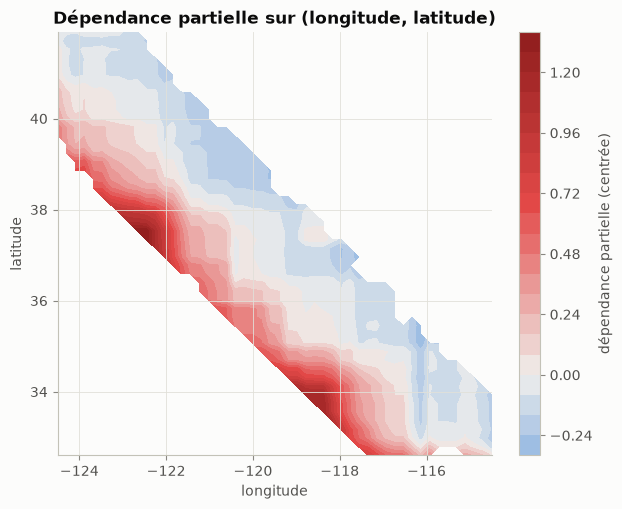

In [22]:
glon = np.linspace(-124.5, -114.5, 50)
glat = np.linspace(32.6, 41.9, 50)
LO, LA = np.meshgrid(glon, glat)
pd_loc = gbh.partial_dependence(np.c_[LA.ravel(), LO.ravel()], [6, 7]).reshape(LO.shape)
fig, ax = plt.subplots(figsize=(7, 5.5))
# on masque les zones sans données (distance au quartier le plus proche > 0,25 degré)
ref = Xh_tr[:3000, 6:8]
d2 = ((LA.ravel()[:, None] - ref[:, 0]) ** 2 + (LO.ravel()[:, None] - ref[:, 1]) ** 2).min(1)
inside = d2.reshape(LO.shape) < 0.25 ** 2
pdc = pd_loc - np.median(pd_loc[inside])
lim = np.abs(pdc[inside]).max()
cs = ax.contourf(LO, LA, np.ma.masked_where(~inside, pdc), levels=21, cmap=DIV, vmin=-lim, vmax=lim)
fig.colorbar(cs, ax=ax, label="dépendance partielle (centrée)")
ax.set_title("Dépendance partielle sur (longitude, latitude)")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
plt.show()